# 02: Decarbonisation Scenarios, MACC & Net-Zero Pathway

**Question for the board:** *Which reduction levers should EcoNaija Manufacturing Ltd fund, in what order, and do they put the company on an SBTi-aligned path?*

Method (see `src/carbon/scenarios.py` and `docs/methodology.md`):
1. Baseline = 2025 annual activity by site.
2. Nine levers (`data/reference/reduction_levers.csv`) are applied **in order** to the residual activity, so they are never double-counted. Abatement counts every factor component (e.g. avoided diesel cuts Scope 1 combustion **and** Scope 3 Cat 3 upstream).
3. Annualised cost = capex × CRF(12%, lifetime) + opex − fuel/energy savings.
4. Pathway to 2035 with +2%/yr growth. Levers **phase in** over `ramp_years`. **Low/high bands** come from each lever's effectiveness range. The comparison is SBTi minimum rates (Scope 1+2: 4.2%/yr, Scope 3: 2.5%/yr, from 2023).
5. Market-based Scope 2 only counts instruments that pass the **GHG Protocol Scope 2 Quality Criteria**.

> Activity data and company profile are **synthetic**. Fuel prices, tariff and FX are **sourced 2026 Nigerian market values**. Lever capex and opex are **documented assumptions**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import pandas as pd
from IPython.display import Image, Markdown, display
from carbon import load_activity, load_factors, calculate_emissions
from carbon.grid_factor import sensitivity as grid_sensitivity
from carbon.scenarios import (load_levers, load_cost_assumptions, load_profile, load_instruments, baseline_activity,
                              apply_levers, pathway_range, sensitivity_analysis, intensity_metrics, scope2_dual,
                              validate_instruments, eligible_kwh_by_year)
pd.set_option('display.float_format', '{:,.1f}'.format)

activity, factors = load_activity(), load_factors()
emissions = calculate_emissions(activity, factors)
A, levers = load_cost_assumptions(), load_levers()
base = baseline_activity(activity, 2025)
pd.read_csv('../data/reference/cost_assumptions.csv')[['parameter', 'value', 'unit', 'source']]

,parameter,value,unit,source
0,fx_ngn_per_usd,"1,350.0",NGN per USD,Assumption based on NAFEM / market rates Sep 2...
1,diesel_price_ngn_per_litre,"1,900.0",NGN per litre,Lagos depot N1850-1900/L (19-23 Oct 2026); Dan...
2,petrol_price_ngn_per_litre,"1,400.0",NGN per litre,Median depot PMS ~N1353/L (15 Sep 2026); NBS p...
3,grid_tariff_ngn_per_kwh,209.5,NGN per kWh,NERC Band A tariff N209.50/kWh (MYTO supplemen...
4,flight_domestic_usd_per_pkm,0.2,USD per passenger-km,Assumption: ~USD110 one-way Lagos-Abuja (~520 km)
5,flight_longhaul_usd_per_pkm,0.1,USD per passenger-km,Assumption: ~USD900 economy return Lagos-Londo...
6,refrigerant_usd_per_kg,25.0,USD per kg,Assumption: R-410A recharge cost
7,landfill_gate_fee_usd_per_tonne,25.0,USD per tonne,Assumption: private waste collection and dispo...
8,discount_rate,0.1,fraction,Assumption: real USD cost of capital for Niger...
9,bau_growth_rate,0.0,fraction per year,Assumption: business-as-usual activity growth ...


## 0. Nigeria grid factor: split by scope
The lifecycle factor is split into Scope 2 (combustion at power plants) and Scope 3 Cat 3 (upstream gas supply, T&D losses). The fleet-efficiency assumption drives the uncertainty.

In [2]:
pd.DataFrame(grid_sensitivity()).T.rename_axis('fleet efficiency')

,primary,wtt,td_losses,total
fleet efficiency,,,,
0.3,0.5,0.1,0.0,0.6
0.3,0.4,0.1,0.0,0.5
0.4,0.4,0.1,0.0,0.5


## 1. Lever results

In [3]:
results, residual = apply_levers(base, levers, factors, A, 2025)
results[['lever_id', 'lever', 'accounting', 'start_year', 'ramp_years', 'abatement_tco2e', 'abatement_s12', 'abatement_s3',
         'capex_usd', 'annual_savings_usd', 'cost_per_tco2e_usd', 'simple_payback_years']].sort_values('cost_per_tco2e_usd')

,lever_id,lever,accounting,start_year,ramp_years,abatement_tco2e,abatement_s12,abatement_s3,capex_usd,annual_savings_usd,cost_per_tco2e_usd,simple_payback_years
4,L5,Travel policy (virtual-first + economy-only),location,2026,1,67.0,0.0,67.0,"15,000.0","58,574.5",-811.8,0.3
1,L2,Solar-battery hybrid at Port Harcourt Plant,location,2027,1,265.6,215.2,50.5,"216,000.0","113,786.0",-292.8,2.0
0,L1,Energy efficiency (LED + inverter ACs + motor ...,location,2026,2,139.7,109.8,29.8,"70,000.0","40,885.0",-189.7,1.8
2,L3,Rooftop solar PV (grid-tied) at Lagos HQ & Abu...,location,2026,1,111.9,88.0,23.9,"111,000.0","32,757.5",-129.6,3.8
5,L6,Hybrid working policy (2 remote days per week),location,2026,1,83.0,0.0,83.0,0.0,0.0,0.0,NaN
8,L9,Renewable PPA / I-RECs for Port Harcourt Plant...,market,2027,1,226.7,226.7,0.0,0.0,0.0,48.1,NaN
3,L4,Refrigerant leak detection & maintenance progr...,location,2026,1,61.9,61.9,0.0,"8,000.0",804.4,61.5,NaN
6,L7,Waste segregation & recycling programme,location,2027,2,37.2,0.0,37.2,"4,000.0","1,788.8",116.0,NaN
7,L8,Supplier engagement programme (top 20 suppliers),location,2027,3,120.5,0.0,120.5,0.0,0.0,249.0,NaN


## 2. Marginal abatement cost curve

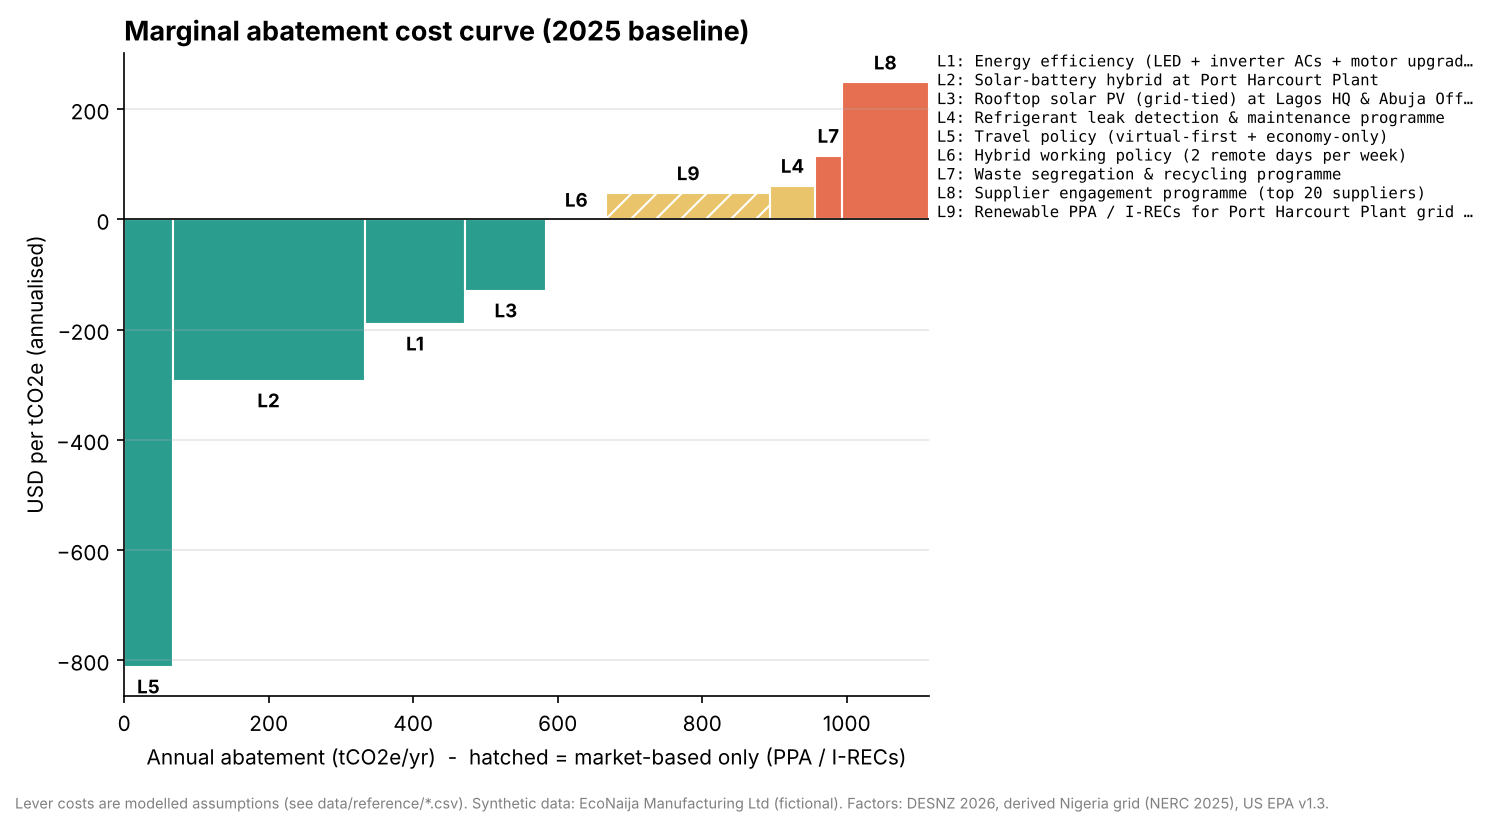

In [4]:
display(Image('../reports/figures/05_macc_curve.png'))

## 3. Pathway vs SBTi-aligned target (phased, with uncertainty)

In [5]:
path = pathway_range(emissions, base, levers, factors, A)
path[path.year.isin([2023, 2025, 2027, 2030, 2035])][
    ['year', 'actual', 'bau', 'with_levers_location', 'with_levers_market', 'with_levers_market_lower',
     'with_levers_market_upper', 'sbti_target']].set_index('year').T

year,2023,2025,2027,2030,2035
actual,"4,727.9","4,283.5",NaN,NaN,NaN
bau,NaN,"4,283.5","4,456.5","4,729.3","5,221.6"
with_levers_location,NaN,"4,283.5","3,636.8","3,750.1","4,140.4"
with_levers_market,NaN,"4,283.5","3,400.9","3,499.8","3,864.1"
with_levers_market_lower,NaN,"4,283.5","3,227.7","3,267.6","3,607.7"
with_levers_market_upper,NaN,"4,283.5","3,622.6","3,787.7","4,181.9"
sbti_target,"4,727.9","4,415.6","4,103.3","3,634.8","2,854.0"


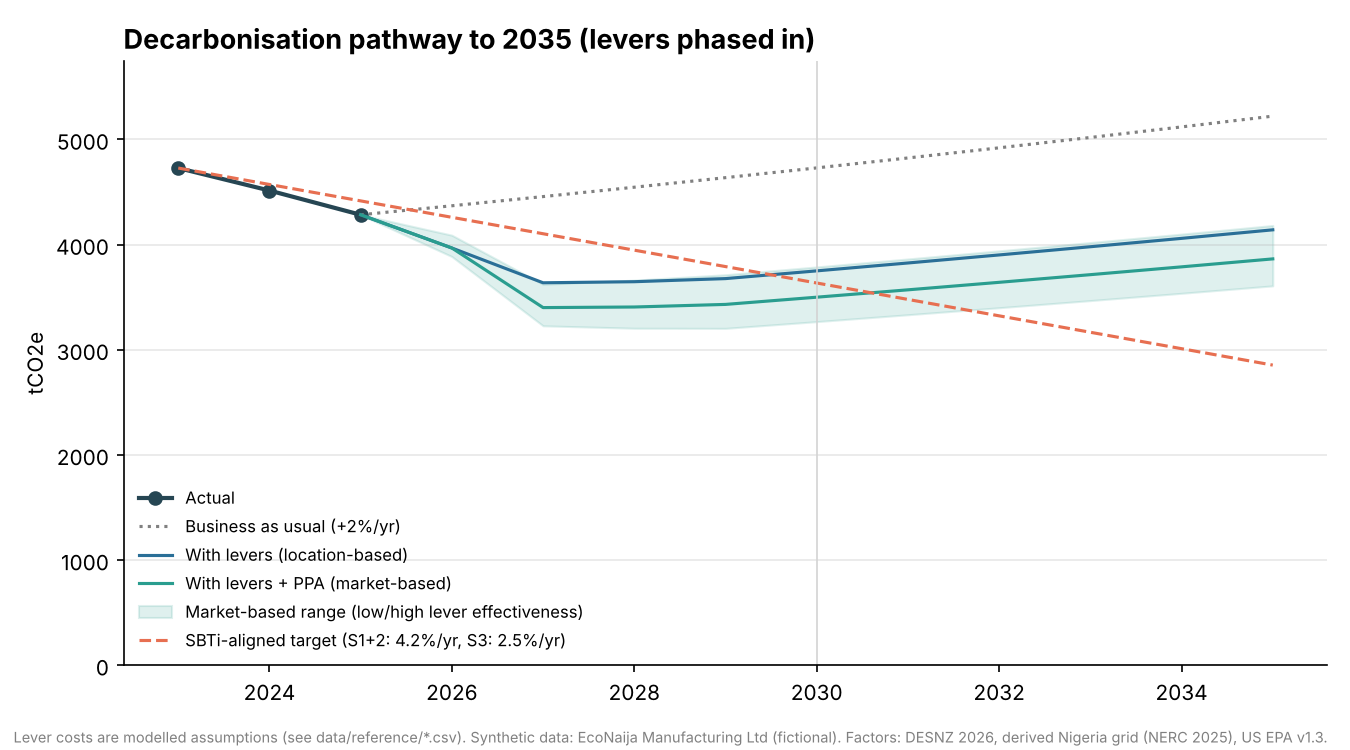

In [6]:
display(Image('../reports/figures/06_decarbonisation_pathway.png'))

## 4. Sensitivity: what moves the business case and the target gap?

In [7]:
sens = sensitivity_analysis(activity, emissions, levers, factors, A)
sens

,parameter,net_saving_low,net_saving_high,gap_low,gap_high,saving_swing
0,Lever effectiveness low / high,"52,134.8","182,358.1",152.9,-367.2,"130,223.3"
1,FX (₦/USD) ±25%,"186,627.7","86,665.8",-135.0,-135.0,"99,961.9"
2,Diesel price ±30%,"90,015.7","158,287.4",-135.0,-135.0,"68,271.6"
3,Grid tariff ±30%,"102,058.8","146,244.3",-135.0,-135.0,"44,185.5"
4,Discount rate 8% / 18%,"136,872.6","103,222.5",-135.0,-135.0,"33,650.1"
5,Lever capex ±25%,"140,612.7","107,690.4",-135.0,-135.0,"32,922.3"
6,BAU growth 0% / 4%,"124,151.6","124,151.6",-464.9,221.9,0.0


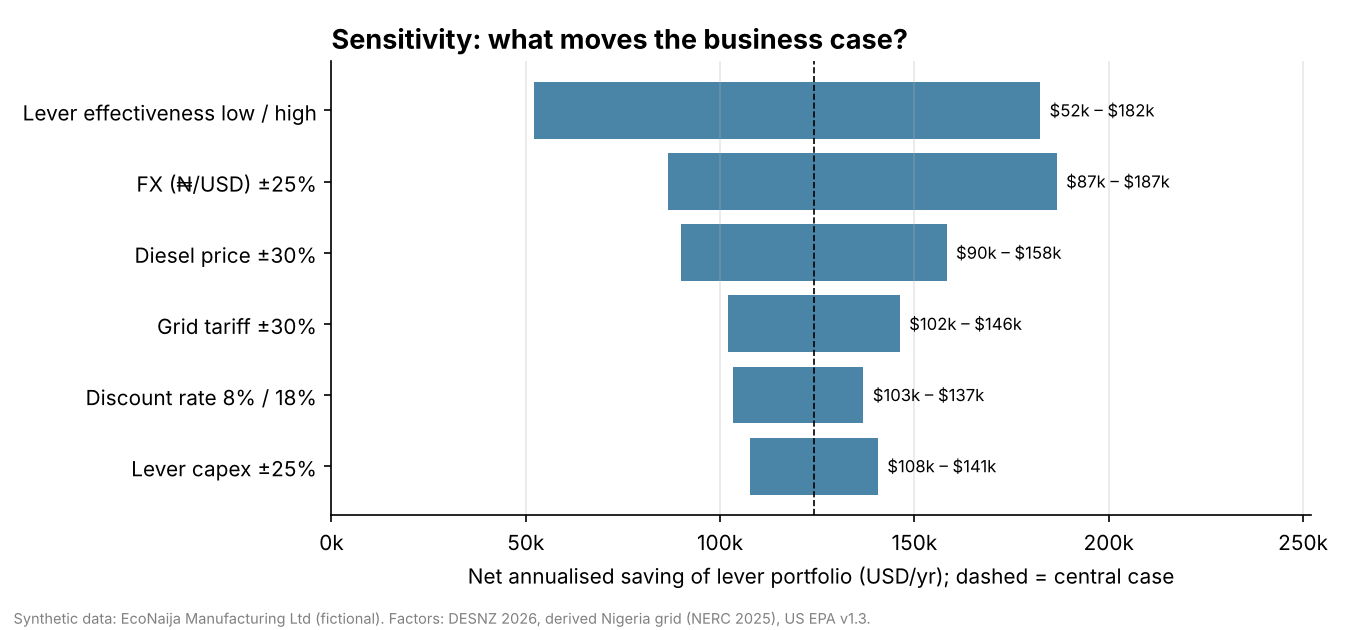

In [8]:
display(Image('../reports/figures/07_sensitivity_tornado.png'))

## 5. Market-based Scope 2: instrument quality checks

In [9]:
validated = validate_instruments(load_instruments())
display(validated[['instrument_id', 'instrument_type', 'generation_year', 'generation_country', 'mwh', 'eligible', 'failure_reasons']])
scope2_dual(emissions, eligible_kwh_by_year(validated))

,instrument_id,instrument_type,generation_year,generation_country,mwh,eligible,failure_reasons
0,IREC-2025-001,I-REC (unbundled certificate),2025,NG,250,True,
1,IREC-2025-002,I-REC (unbundled certificate),2025,NG,120,False,not retired for company
2,IREC-2023-003,I-REC (unbundled certificate),2023,NG,100,False,vintage mismatch
3,IREC-2025-004,I-REC (unbundled certificate),2025,GH,80,False,different market
4,PPA-2025-005,Physical PPA (no certificates),2025,NG,150,False,no attribute claim; not retired for company; n...


,year,kwh,location_tco2e,contractual_kwh,market_tco2e
0,2023,"2,376,020.8",990.5,0.0,990.5
1,2024,"2,260,844.9",942.5,0.0,942.5
2,2025,"2,195,497.5",915.2,"250,000.0",811.0


## 6. Intensity metrics

In [10]:
intensity_metrics(emissions, load_profile())[['year', 'tco2e', 'tco2e_per_employee', 'tco2e_per_usd_m_revenue', 'kgco2e_per_tonne_product']]

,year,tco2e,tco2e_per_employee,tco2e_per_usd_m_revenue,kgco2e_per_tonne_product
0,2023,"4,727.9",11.3,124.4,90.9
1,2024,"4,514.0",10.4,110.1,83.6
2,2025,"4,283.5",9.5,97.4,77.9


## 7. Recommendations (generated from the results above)

In [11]:
b25 = emissions.loc[emissions.year == 2025, 'tco2e'].sum()
phys = results[results.accounting == 'location']; neg = results[results.cost_per_tco2e_usd < 0]
l2 = results.set_index('lever_id').loc['L2']; p30 = path[path.year == 2030].iloc[0]
Markdown(f'''
1. **Fund the {len(neg)} cost-negative levers first** ({', '.join(neg.sort_values('cost_per_tco2e_usd').lever_id)}). They deliver {neg.abatement_tco2e.sum()/results.abatement_tco2e.sum():.0%} of abatement and save money.
   The **Port Harcourt solar-battery hybrid** is the flagship: {l2.abatement_tco2e:,.0f} tCO2e/yr with a ~{l2.simple_payback_years:.1f}-year payback.
2. **Physical levers cut {phys.abatement_tco2e.sum():,.0f} tCO2e/yr ({phys.abatement_tco2e.sum()/b25:.0%} of 2025).** In 2030 the location-based gap is
   {p30.with_levers_location - p30.sbti_target:+,.0f} t. Adding quality-assured renewable contracts (L9) brings the central case to
   {p30.with_levers_market - p30.sbti_target:+,.0f} t (range {p30.with_levers_market_lower - p30.sbti_target:+,.0f} to {p30.with_levers_market_upper - p30.sbti_target:+,.0f} t).
3. **The business case is robust:** the portfolio stays cash-positive in every sensitivity case (min ${sens[['net_saving_low','net_saving_high']].min().min():,.0f}/yr).
   **{sens.iloc[0].parameter}** moves it most.
4. **Plan a second wave by ~2029.** Growth erodes the gains toward 2035: deeper supplier engagement, fleet conversion, more on-site solar.
5. **Fix the data first.** Supplier-specific Scope 3 data and metered generator diesel are the largest sources of uncertainty.
''')


1. **Fund the 4 cost-negative levers first** (L5, L2, L1, L3). They deliver 52% of abatement and save money.
   The **Port Harcourt solar-battery hybrid** is the flagship: 266 tCO2e/yr with a ~2.0-year payback.
2. **Physical levers cut 887 tCO2e/yr (21% of 2025).** In 2030 the location-based gap is
   +115 t. Adding quality-assured renewable contracts (L9) brings the central case to
   -135 t (range -367 to +153 t).
3. **The business case is robust:** the portfolio stays cash-positive in every sensitivity case (min $52,135/yr).
   **Lever effectiveness low / high** moves it most.
4. **Plan a second wave by ~2029.** Growth erodes the gains toward 2035: deeper supplier engagement, fleet conversion, more on-site solar.
5. **Fix the data first.** Supplier-specific Scope 3 data and metered generator diesel are the largest sources of uncertainty.
